In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
import warnings
warnings.filterwarnings('ignore')


In [2]:
df = pd.read_excel("Code Datasets.xlsx", sheet_name="BDI")
df.head()

,Date (DD/MM/YYYY),Date,Price,Year,Quarter,QY,BDI_AVG
0,2010-01-01,2010-01-01,2848,2010.0,Q1,Q1 2010,2861.333333
1,2010-02-01,2010-02-01,2738,2010.0,Q2,Q2 2010,3279.333333
2,2010-03-01,2010-03-01,2998,2010.0,Q3,Q3 2010,2375.333333
3,2010-04-01,2010-04-01,3354,2010.0,Q4,Q4 2010,2183.333333
4,2010-05-01,2010-05-01,4078,2011.0,Q1,Q1 2011,1296.000000


In [3]:
dfBDI = df[['Date', 'Price']]
dfBDI.head()

,Date,Price
0,2010-01-01,2848
1,2010-02-01,2738
2,2010-03-01,2998
3,2010-04-01,3354
4,2010-05-01,4078


In [4]:
dfBDI['Date'] = pd.to_datetime(dfBDI['Date'])
dfBDI = dfBDI.sort_values('Date').reset_index(drop=True)

dfBDI.set_index('Date', inplace=True)

dfBDI.index = pd.DatetimeIndex(dfBDI.index).to_period('M')

dfBDI['Price'].describe().round(2)


count     201.00
mean     1512.57
std       798.82
min       317.00
25%       934.00
50%      1356.00
75%      1895.00
max      5167.00
Name: Price, dtype: float64

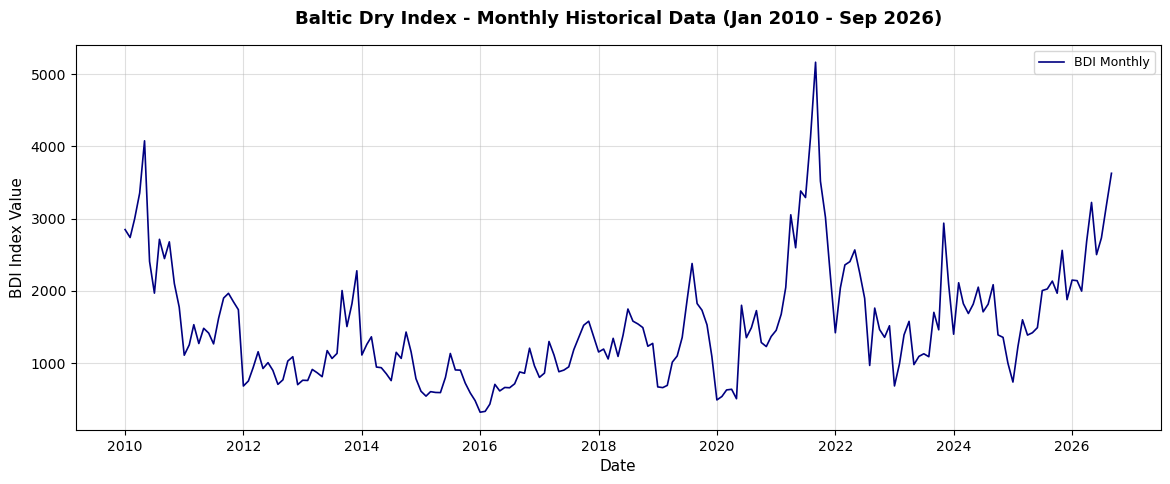

In [5]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(dfBDI.index.to_timestamp(), dfBDI['Price'],
        color='navy', linewidth=1.2, label='BDI Monthly')

ax.set_title('Baltic Dry Index - Monthly Historical Data (Jan 2010 - Sep 2026)',
             fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Date', fontsize=11)
ax.set_ylabel('BDI Index Value', fontsize=11)
ax.legend(fontsize=9)
ax.grid(alpha=0.4)

plt.savefig("Monthly BDI chart.png", dpi=300, bbox_inches='tight')

plt.show()



In [6]:
def run_adf_test(series, series_name):
    result = adfuller(series.dropna(), autolag='AIC')
    print(f"ADF Test - {series_name}")
    print(f"  Test Statistic : {result[0]:.4f}")
    print(f"  p-value        : {result[1]:.4f}")
    print(f"  Critical Values:")
    for key, value in result[4].items():
        print(f"    {key}: {value:.4f}")
    if result[1] < 0.05:
        print(f"  STATIONARY (reject H0 at 5% significance)")
    else:
        print(f"  NON-STATIONARY (fail to reject H0 — differencing needed)")
    print()

run_adf_test(dfBDI['Price'], 'BDI in Levels')

dfBDI['BDI_diff'] = dfBDI['Price'].diff()
run_adf_test(dfBDI['BDI_diff'].dropna(), 'BDI First Difference')



ADF Test - BDI in Levels
  Test Statistic : -3.3170
  p-value        : 0.0141
  Critical Values:
    1%: -3.4642
    5%: -2.8764
    10%: -2.5747
  STATIONARY (reject H0 at 5% significance)

ADF Test - BDI First Difference
  Test Statistic : -8.8423
  p-value        : 0.0000
  Critical Values:
    1%: -3.4642
    5%: -2.8764
    10%: -2.5747
  STATIONARY (reject H0 at 5% significance)



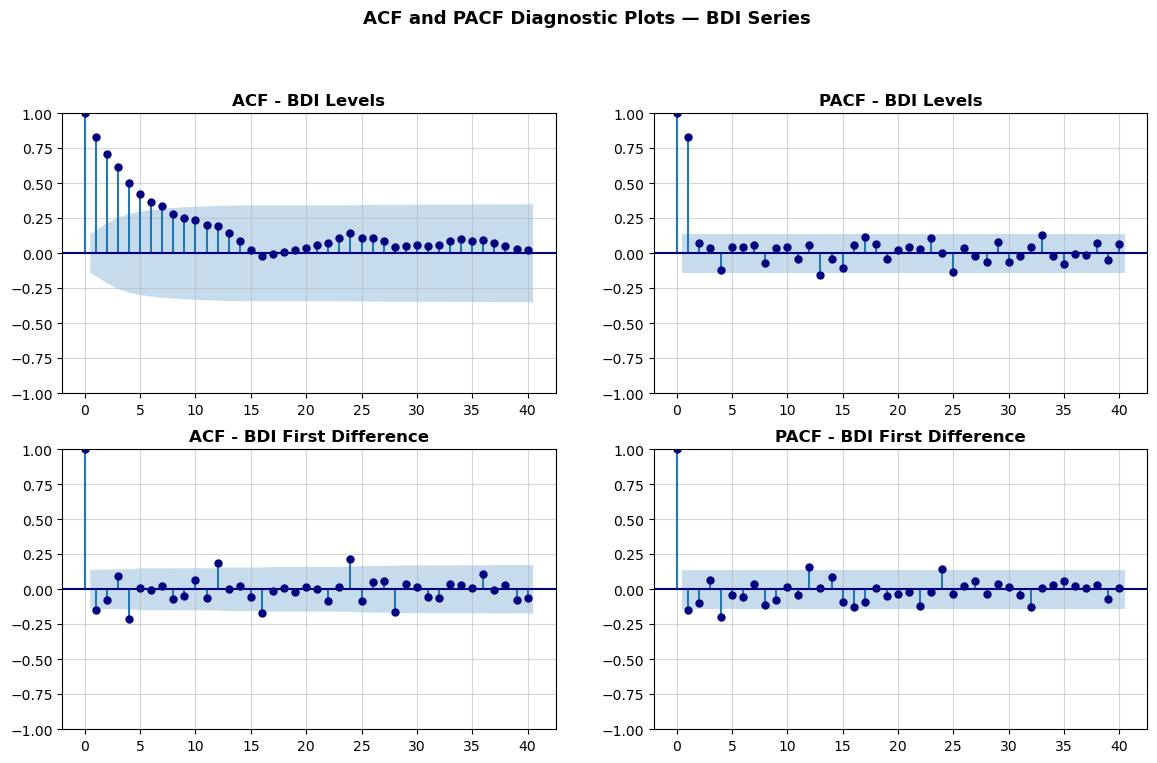

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

plot_acf(dfBDI['Price'].dropna(), lags=40, ax=axes[0,0], color='navy')
axes[0,0].set_title('ACF - BDI Levels', fontweight='bold')

plot_pacf(dfBDI['Price'].dropna(), lags=40, ax=axes[0,1],
          method='ywm', color='navy')
axes[0,1].set_title('PACF - BDI Levels', fontweight='bold')

plot_acf(dfBDI['BDI_diff'].dropna(), lags=40, ax=axes[1,0], color='navy')
axes[1,0].set_title('ACF - BDI First Difference', fontweight='bold')

plot_pacf(dfBDI['BDI_diff'].dropna(), lags=40, ax=axes[1,1],
          method='ywm', color='navy')
axes[1,1].set_title('PACF - BDI First Difference', fontweight='bold')

for ax in axes.flatten():
    ax.grid(alpha=0.5)

plt.suptitle('ACF and PACF Diagnostic Plots — BDI Series',
             fontsize=13, fontweight='bold', y=1.01)

plt.savefig("ACF_PACF.png", dpi=300, bbox_inches='tight')

plt.show()

In [8]:
p_values = range(0, 4)
q_values = range(0, 4)
d = 1

results_table = []

for p in p_values:
    for q in q_values:
        try:
            model = ARIMA(dfBDI['Price'], order=(p, d, q))
            fitted = model.fit()
            results_table.append({
                'Order': f'ARIMA({p},{d},{q})',
                'AIC': round(fitted.aic, 2),
                'BIC': round(fitted.bic, 2),
                'Log-Likelihood': round(fitted.llf, 2)
            })
        except:
            pass

results_df = pd.DataFrame(results_table)
results_df = results_df.sort_values('AIC').reset_index(drop=True)

print("Model Selection Results (sorted by AIC):")
print(results_df.to_string(index=False))
best_order_str = results_df.iloc[0]['Order']
best_p = int(best_order_str[6])
best_q = int(best_order_str[10])
print(f"\nBest model selected: {best_order_str}")
best_p = 1
best_q = 1
best_order_str = f'ARIMA({best_p},{d},{best_q})'
print(f"\nSelected model: {best_order_str}")
print(f"AIC: {results_df[results_df['Order'] == best_order_str]['AIC'].values[0]}")
print(f"BIC: {results_df[results_df['Order'] == best_order_str]['BIC'].values[0]}")
print(f"\nNote: ARIMA(3,1,3) has lower AIC by 1.40 points (negligible difference).")
print(f"ARIMA(1,1,1) selected on BIC, parsimony, and ACF/PACF visual confirmation.")


Model Selection Results (sorted by AIC):
       Order     AIC     BIC  Log-Likelihood
ARIMA(3,1,3) 2988.98 3012.07        -1487.49
ARIMA(1,1,1) 2990.38 3000.28        -1492.19
ARIMA(3,1,2) 2991.18 3010.97        -1489.59
ARIMA(2,1,1) 2992.29 3005.48        -1492.14
ARIMA(2,1,3) 2992.35 3012.14        -1490.17
ARIMA(1,1,2) 2993.22 3006.41        -1492.61
ARIMA(2,1,2) 2993.34 3009.83        -1491.67
ARIMA(0,1,1) 2993.47 3000.06        -1494.73
ARIMA(3,1,1) 2993.88 3010.37        -1491.94
ARIMA(0,1,2) 2994.14 3004.03        -1494.07
ARIMA(1,1,0) 2994.28 3000.87        -1495.14
ARIMA(2,1,0) 2994.36 3004.26        -1494.18
ARIMA(1,1,3) 2995.05 3011.55        -1492.53
ARIMA(3,1,0) 2995.37 3008.56        -1493.68
ARIMA(0,1,3) 2995.97 3009.16        -1493.98
ARIMA(0,1,0) 2996.71 3000.01        -1497.35

Best model selected: ARIMA(3,1,3)

Selected model: ARIMA(1,1,1)
AIC: 2990.38
BIC: 3000.28

Note: ARIMA(3,1,3) has lower AIC by 1.40 points (negligible difference).
ARIMA(1,1,1) selected on BIC,

                               SARIMAX Results                                
Dep. Variable:                  Price   No. Observations:                  201
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -1492.192
Date:                Fri, 06 Nov 2026   AIC                           2990.385
Time:                        00:30:14   BIC                           3000.280
Sample:                    01-31-2010   HQIC                          2994.389
                         - 09-30-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8074      0.061     13.159      0.000       0.687       0.928
ma.L1         -0.9498      0.042    -22.797      0.000      -1.031      -0.868
sigma2       1.77e+05   1.26e+04     14.083      0.0

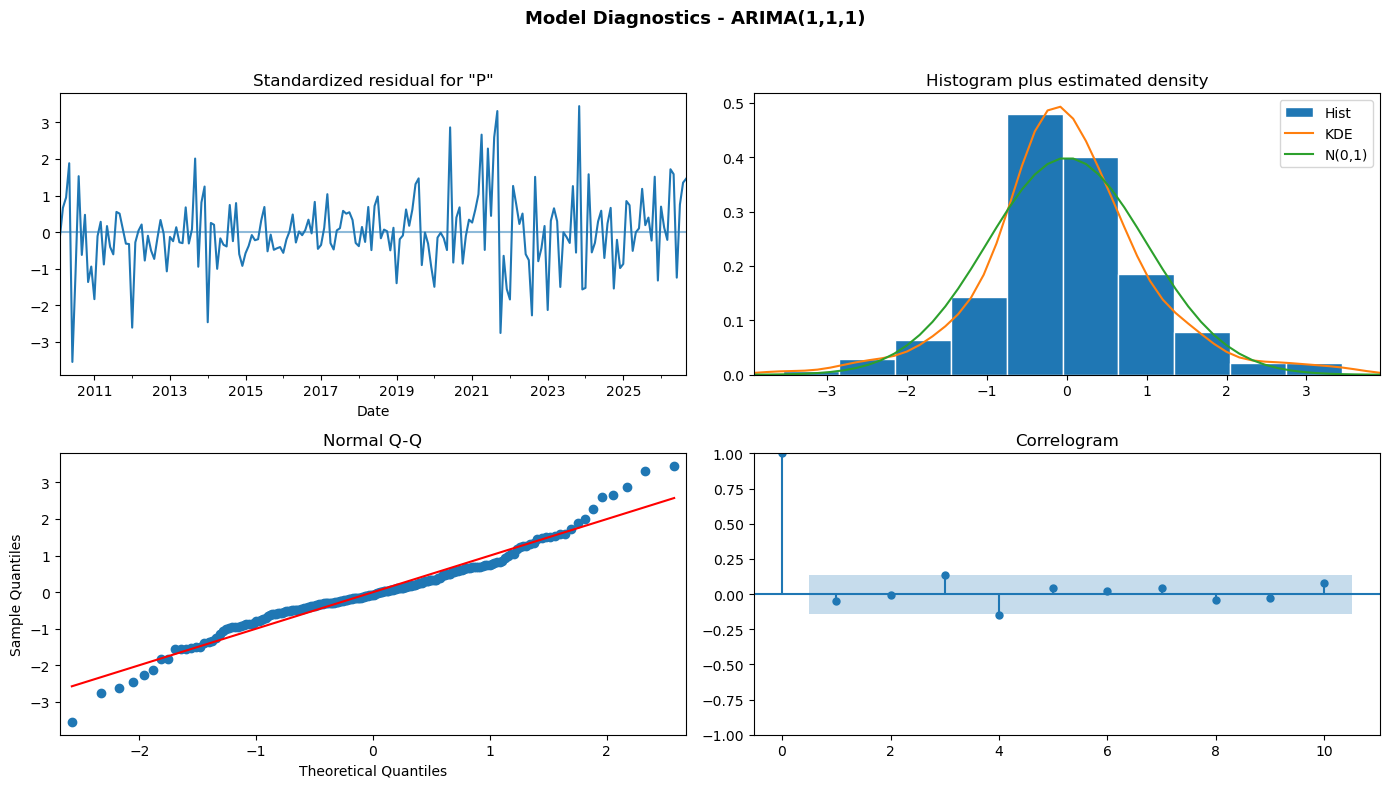

In [14]:
best_model = ARIMA(dfBDI['Price'], order=(best_p, d, best_q))
best_fitted = best_model.fit()

print(best_fitted.summary())

lb_test = acorr_ljungbox(best_fitted.resid, lags=[10, 20], return_df=True)
print("\nLjung-Box Test on Residuals:")
print(lb_test)
print("\nIf all p-values > 0.05, residuals are white noise — model is adequate.")

fig = plt.figure(figsize=(14, 8))
best_fitted.plot_diagnostics(fig=fig)
fig.suptitle('Model Diagnostics - ARIMA(1,1,1)',
             fontsize=13, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig("Diagnostics.png", dpi=300, bbox_inches='tight')

plt.show()

Training period: 2010-01 to 2024-12
Test period:     2025-01 to 2026-09
Training observations: 180
Test observations:     21

Backtest Results — ARIMA(1,1,1)
  Mean Absolute Error (MAE):             823.5 BDI points
  Mean Absolute Percentage Error (MAPE): 34.95%
  Root Mean Squared Error (RMSE):        998.4 BDI points

Month-by-Month Comparison:
   Month  Actual BDI  Forecast BDI  Error  Abs % Error
Jan 2025         735          1065   -330         44.9
Feb 2025        1229          1123    106          8.6
Mar 2025        1598          1172    426         26.7
Apr 2025        1386          1214    172         12.4
May 2025        1418          1250    168         11.9
Jun 2025        1489          1280    209         14.0
Jul 2025        2003          1306    697         34.8
Aug 2025        2025          1329    696         34.4
Sep 2025        2134          1347    787         36.9
Oct 2025        1966          1364    602         30.6
Nov 2025        2560          1377   1183    

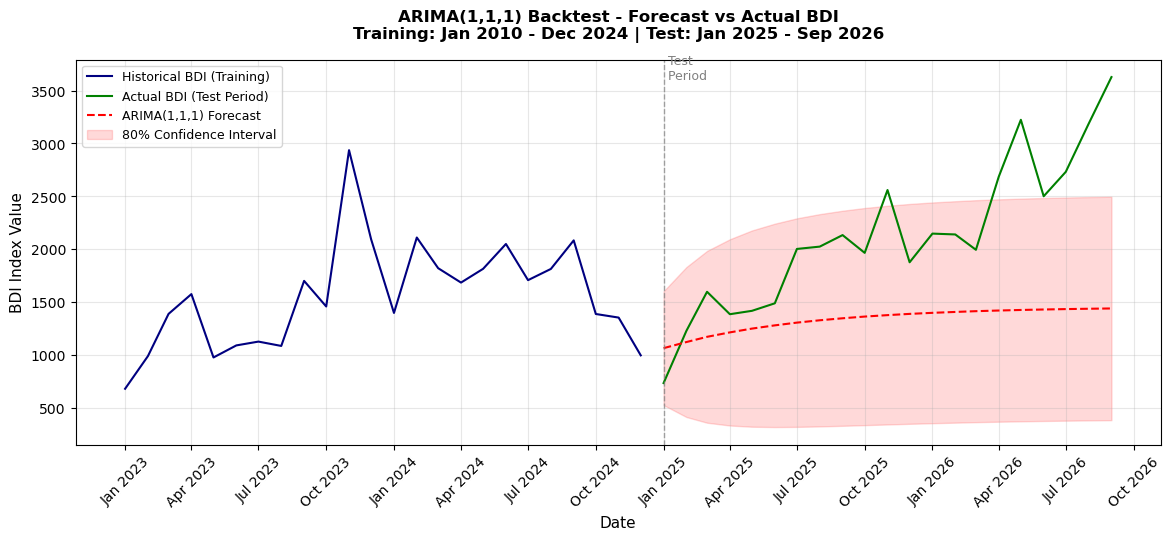

In [10]:
train = dfBDI['Price'][:'2024-12']
test = dfBDI['Price']['2025-01':]

print(f"Training period: {train.index[0]} to {train.index[-1]}")
print(f"Test period:     {test.index[0]} to {test.index[-1]}")
print(f"Training observations: {len(train)}")
print(f"Test observations:     {len(test)}\n")

backtest_model = ARIMA(train, order=(1, 1, 1))
backtest_fitted = backtest_model.fit()

backtest_forecast = backtest_fitted.get_forecast(steps=len(test))
backtest_mean = backtest_forecast.predicted_mean.values
backtest_ci = backtest_forecast.conf_int(alpha=0.20)
backtest_lower = backtest_ci.iloc[:, 0].values
backtest_upper = backtest_ci.iloc[:, 1].values

actual = test.values

mae = np.mean(np.abs(actual - backtest_mean))
mape = np.mean(np.abs((actual - backtest_mean) / actual)) * 100
rmse = np.sqrt(np.mean((actual - backtest_mean) ** 2))

print("Backtest Results — ARIMA(1,1,1)")
print(f"  Mean Absolute Error (MAE):             {mae:.1f} BDI points")
print(f"  Mean Absolute Percentage Error (MAPE): {mape:.2f}%")
print(f"  Root Mean Squared Error (RMSE):        {rmse:.1f} BDI points")

backtest_df = pd.DataFrame({
    'Month': test.index.to_timestamp().strftime('%b %Y'),
    'Actual BDI': actual.round(0).astype(int),
    'Forecast BDI': backtest_mean.round(0).astype(int),
    'Error': (actual - backtest_mean).round(0).astype(int),
    'Abs % Error': (np.abs((actual - backtest_mean) / actual) * 100).round(1)
})
print("\nMonth-by-Month Comparison:")
print(backtest_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(14, 5))

train_recent = train['2023':]
ax.plot(train_recent.index.to_timestamp(), train_recent.values,
        color='navy', linewidth=1.5, label='Historical BDI (Training)')

ax.plot(test.index.to_timestamp(), actual,
        color='green', linewidth=1.5, label='Actual BDI (Test Period)')

ax.plot(test.index.to_timestamp(), backtest_mean,
        color='red', linewidth=1.5, linestyle='--',
        label='ARIMA(1,1,1) Forecast')

ax.fill_between(test.index.to_timestamp(),
                backtest_lower, backtest_upper,
                alpha=0.15, color='red', label='80% Confidence Interval')

ax.axvline(x=pd.Timestamp('2025-01-01'),
           color='gray', linewidth=1, linestyle='--', alpha=0.7)
ax.text(pd.Timestamp('2025-01-01'), ax.get_ylim()[1] * 0.95,
        ' Test\n Period', fontsize=9, color='gray')

ax.set_title('ARIMA(1,1,1) Backtest - Forecast vs Actual BDI\n'
             'Training: Jan 2010 - Dec 2024 | Test: Jan 2025 - Sep 2026',
             fontsize=12, fontweight='bold', pad=15)

ax.set_xlabel('Date', fontsize=11)
ax.set_ylabel('BDI Index Value', fontsize=11)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.xticks(rotation=45)

plt.savefig("Backtest.png", dpi=300, bbox_inches='tight')

plt.show()

In [11]:
forecast_steps = 24
forecast_result = best_fitted.get_forecast(steps=forecast_steps)
forecast_mean = forecast_result.predicted_mean
forecast_ci = forecast_result.conf_int(alpha=0.20)

forecast_index = forecast_mean.index.to_timestamp()

base_forecast = forecast_mean.values
lower_ci = forecast_ci.iloc[:, 0].values   # Bear
upper_ci = forecast_ci.iloc[:, 1].values   # Bull

base_forecast = np.maximum(base_forecast, 200)
lower_ci = np.maximum(lower_ci, 200)
upper_ci = np.maximum(upper_ci, 200)

forecast_df = pd.DataFrame({
    'Month': forecast_index.strftime('%b %Y'),
    'Bear': lower_ci.round(0).astype(int),
    'Base': base_forecast.round(0).astype(int),
    'Bull': upper_ci.round(0).astype(int)
})

print("Monthly BDI Forecast - Sep 2026 through Aug 2028:")
print(forecast_df.to_string(index=False))

Monthly BDI Forecast - Sep 2026 through Aug 2028:
   Month  Bear  Base  Bull
Oct 2026  2861  3400  3940
Nov 2026  2506  3217  3927
Dec 2026  2253  3068  3884
Jan 2027  2061  2949  3836
Feb 2027  1912  2852  3792
Mar 2027  1794  2774  3754
Apr 2027  1699  2711  3722
May 2027  1622  2660  3697
Jun 2027  1560  2619  3678
Jul 2027  1508  2586  3663
Aug 2027  1465  2559  3652
Sep 2027  1429  2537  3645
Oct 2027  1398  2520  3641
Nov 2027  1372  2506  3639
Dec 2027  1350  2494  3639
Jan 2028  1330  2485  3640
Feb 2028  1312  2478  3643
Mar 2028  1296  2472  3647
Apr 2028  1282  2467  3651
May 2028  1269  2463  3657
Jun 2028  1257  2460  3662
Jul 2028  1246  2457  3668
Aug 2028  1235  2455  3675
Sep 2028  1225  2453  3682


In [12]:
forecast_full = pd.DataFrame({
    'Bear': lower_ci,
    'Base': base_forecast,
    'Bull': upper_ci
}, index=forecast_index)

forecast_full['Quarter'] = pd.PeriodIndex(
    forecast_full.index.to_period('Q'))

quarterly_forecast = forecast_full.groupby(
    'Quarter')[['Bear','Base','Bull']].mean().round(0).astype(int)

quarterly_forecast.index = [
    f"{p.year} Q{p.quarter}" for p in quarterly_forecast.index
]
quarterly_forecast.index.name = 'Quarter'

print("Quarterly Average BDI Forecast - Q4 2026 through Q3 2028:")
print(quarterly_forecast.to_string())
quarterly_forecast.to_excel("ARIMA_quarterly_forecast.xlsx", sheet_name="Quarterly Forecast", index=True)


Quarterly Average BDI Forecast - Q4 2026 through Q3 2028:
         Bear  Base  Bull
Quarter                  
2026 Q4  2540  3229  3917
2027 Q1  1922  2858  3794
2027 Q2  1627  2663  3699
2027 Q3  1467  2561  3654
2027 Q4  1373  2507  3640
2028 Q1  1313  2478  3643
2028 Q2  1269  2463  3657
2028 Q3  1235  2455  3675


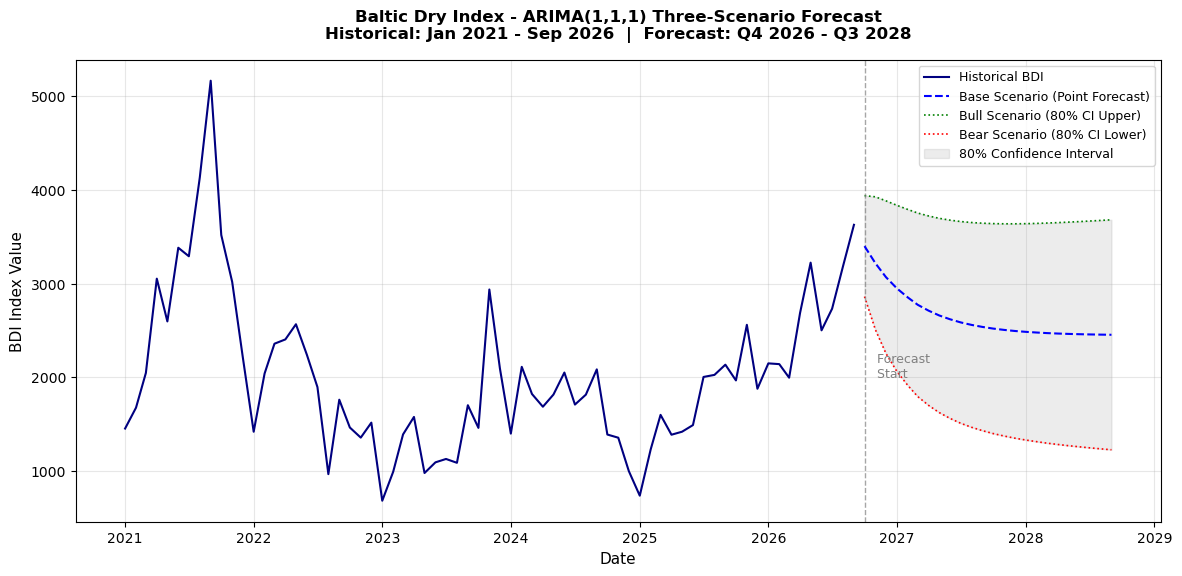

In [13]:
fig, ax = plt.subplots(figsize=(14, 6))

hist_recent = dfBDI['Price']['2021':]
ax.plot(hist_recent.index.to_timestamp(), hist_recent.values,
        color='navy', linewidth=1.5, label='Historical BDI', zorder=3)

ax.plot(forecast_index, base_forecast,
        color='blue', linewidth=1.5, linestyle='--',
        label='Base Scenario (Point Forecast)', zorder=3)
ax.plot(forecast_index, upper_ci,
        color='green', linewidth=1.2, linestyle=':',
        label='Bull Scenario (80% CI Upper)', zorder=2)
ax.plot(forecast_index, lower_ci,
        color='red', linewidth=1.2, linestyle=':',
        label='Bear Scenario (80% CI Lower)', zorder=2)

ax.fill_between(forecast_index, lower_ci, upper_ci,
                alpha=0.15, color='gray', label='80% Confidence Interval')

ax.axvline(x=pd.Timestamp('2026-10-01'),
           color='gray', linewidth=1,
           linestyle='--', alpha=0.7)
ax.text(pd.Timestamp('2026-10-15'),
        2000,
        '  Forecast\n  Start',
        fontsize=9, color='gray')

ax.set_title('Baltic Dry Index - ARIMA(1,1,1) Three-Scenario Forecast\n'
             'Historical: Jan 2021 - Sep 2026  |  Forecast: Q4 2026 - Q3 2028',
             fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Date', fontsize=11)
ax.set_ylabel('BDI Index Value', fontsize=11)
ax.legend(fontsize=9, loc='upper right')
ax.grid(alpha=0.3)

plt.savefig("Forecast.png", dpi=300, bbox_inches='tight')
plt.show()